--- Linear Regression Evaluation ---
MAE: 0.0000
RMSE: 0.0000
R-squared: 1.0000

--- Random Forest Evaluation ---
MAE: 0.3014
RMSE: 0.5461
R-squared: 0.9506



/tmp/ipykernel_13226/2553875560.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


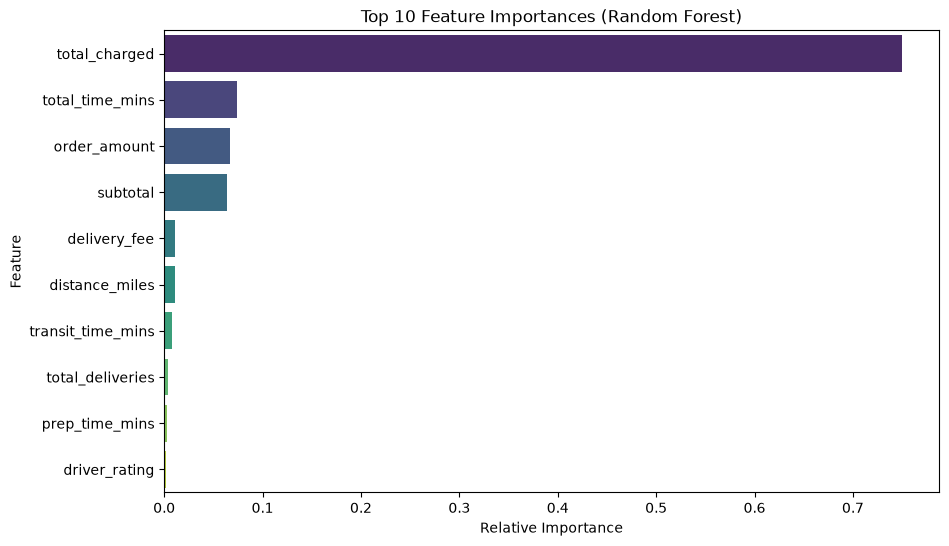

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Part 1: Data Merging & Target Selection
orders = pd.read_csv('../data/orders.csv')
deliveries = pd.read_csv('../data/deliveries.csv')
drivers = pd.read_csv('../data/drivers.csv')
payments = pd.read_csv('../data/payments.csv')

# Merge datasets on common keys
df = pd.merge(orders, deliveries, on='order_id', how='inner')
df = pd.merge(df, drivers, on='driver_id', how='inner')
df = pd.merge(df, payments, on='order_id', how='inner')

# Drop all high-cardinality identifiers and timestamps
cols_to_drop = [
    'order_id', 'customer_id', 'restaurant_id', 'driver_id', 
    'delivery_id', 'payment_id', 'order_timestamp', 'order_time', 
    'actual_delivery_time', 'order_status'
]
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns], errors='ignore')

# Part 2: Feature Engineering & Encoding
# Fill any missing numeric values with the median
df = df.fillna(df.median(numeric_only=True))

# One-hot encode the remaining low-cardinality categorical variables 
# (weather_condition, traffic_condition, vehicle_type, payment_method)
df = pd.get_dummies(df, drop_first=True)

# Define X (features) and y (target)
target_col = 'tip_amount' 
X = df.drop(columns=[target_col])
y = df[target_col]

# Part 3: Data Splitting & Scaling
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Part 4: Model Training
# Baseline Model: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Advanced Model: Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Part 5: Performance Evaluation
def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    print(f"--- {name} Evaluation ---")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R-squared: {r2:.4f}\n")

evaluate_model("Linear Regression", lr_model, X_test_scaled, y_test)
evaluate_model("Random Forest", rf_model, X_test_scaled, y_test)

# Part 6: Feature Importance Analysis
importances = rf_model.feature_importances_
features = X.columns
importance_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.show()